# deepSSF baseline demo

This notebook is a minimal demo of the MoveBench deepSSF baseline APIs.

Legacy exploratory work is preserved in `notebooks/deepssf_legacy.ipynb`.


In [1]:
import torch
from torch.utils.data import DataLoader

from movebench import Study
from movebench.models.deepssf import DeepSSF
from movebench.train import collate_deepssf, eval_deepssf, fit_deepssf


In [2]:
study_id = 'tsavo_lions'  # e.g. Study.list_available()[0]
layers_config = '../configs/layers_local.yaml'
device = torch.device('cpu')

In [3]:
study = Study(study_id)

# # Ensure rasters exist (download if missing), then extract a parametric point store
# # and compute normalization stats. deepSSF uses those stats via ChipDataset.
# try:
#     rep = study.extract_point_features(
#         config=layers_config,
#         splits=['train', 'test'],
#         parametric=True,
#         num_candidates=100,
#         random_seed=0,
#         n_workers=16,
#         skip_existing=True,
#         step_multiplier=2.0,
#         step_q=0.95,
#         gap_q=0.999,
#         bounds_buffer_deg=0.01,
#     )
# except FileNotFoundError as e:
#     if 'rasters' not in str(e):
#         raise
#     study.download_rasters(
#         config=layers_config,
#         splits=['train', 'test'],
#         n_workers=16,
#         skip_existing=True,
#     )
#     rep = study.extract_point_features(
#         config=layers_config,
#         splits=['train', 'test'],
#         parametric=True,
#         num_candidates=100,
#         random_seed=0,
#         n_workers=16,
#         skip_existing=True,
#         step_multiplier=2.0,
#         step_q=0.95,
#         gap_q=0.999,
#         bounds_buffer_deg=0.01,
#     )

# sampler_hash = rep['sampler_hash']
# study.compute_normalization_vals(
#     from_='points',
#     config=layers_config,
#     sampler_hash=sampler_hash,
#     split='train',
#     skip_existing=True,
# )


In [4]:
train_ds = study.deepssf_dataset(
    split='train',
    config=layers_config,
    # normalization_sampler_hash=sampler_hash,
    output_hw=(101, 101),
)
test_ds = study.deepssf_dataset(
    split='test',
    config=layers_config,
    # normalization_sampler_hash=sampler_hash,
    output_hw=(101, 101),
)

train_loader = DataLoader(
    train_ds, 
    batch_size=32, 
    shuffle=True, 
    num_workers=16, 
    collate_fn=collate_deepssf
)
test_loader = DataLoader(
    test_ds, 
    batch_size=32, 
    shuffle=False, 
    num_workers=16, 
    collate_fn=collate_deepssf
)


/Users/justinkay/miniconda3/envs/movebench/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
pixel_size_m = train_ds.chips.pixel_size_m  # meters/pixel in EPSG:3857
pixel_size_m

399.47530773927764

In [6]:
x1, x2, x3, y = next(iter(train_loader))
env_channels = int(x1.shape[1])
image_dim = int(x1.shape[-1])

model = DeepSSF(env_channels, 
                image_dim=image_dim, 
                pixel_size_m=pixel_size_m, 
                device=device)

fit = fit_deepssf(
    model,
    train_loader,
    test_loader,
    device,
    lr_movement=1e-5,
    lr_habitat=1e-4,
    weight_decay=0.0,
    max_steps=2000,
    eval_interval=100,
    patience=50,
    seed=0,
)

train_metrics = eval_deepssf(model, train_loader, device)
test_metrics = eval_deepssf(model, test_loader, device)

fit, train_metrics, test_metrics


/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


{'step': 0.0, 'train_nll': 8.510437412645201, 'val_nll': 11.457612583619664}


/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


{'step': 100.0, 'train_nll': 8.202476525048752, 'val_nll': 10.877233125653841}


/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


{'step': 200.0, 'train_nll': 7.751648674423949, 'val_nll': 10.016411108818335}


... (32 outputs left out)

/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


{'step': 1900.0, 'train_nll': 5.137207632639677, 'val_nll': 6.442940400332139}


/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(
/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


({'best_step': 1200,
  'train': {'nll': 5.246380315129135,
   'n_valid': 1294,
   'topk': {1: 0.29057187017001546,
    5: 0.39258114374034003,
    10: 0.44049459041731065,
    25: 0.4992272024729521,
    50: 0.5633693972179289}},
  'val': {'nll': 6.420758966731791,
   'n_valid': 814,
   'topk': {1: 0.18304668304668303,
    5: 0.25061425061425063,
    10: 0.300982800982801,
    25: 0.35626535626535627,
    50: 0.4213759213759214}},
  'history': [{'step': 0.0,
    'train_nll': 8.510437412645201,
    'val_nll': 11.457612583619664},
   {'step': 100.0,
    'train_nll': 8.202476525048752,
    'val_nll': 10.877233125653841},
   {'step': 200.0,
    'train_nll': 7.751648674423949,
    'val_nll': 10.016411108818335},
   {'step': 300.0,
    'train_nll': 6.999601031013029,
    'val_nll': 8.580238051730818},
   {'step': 400.0,
    'train_nll': 6.275863464685643,
    'val_nll': 7.29632095036987},
   {'step': 500.0,
    'train_nll': 5.926707867676913,
    'val_nll': 6.846575294138465},
   {'step': 60

Visualizing env layer 'dist_water' at channel index 40


/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


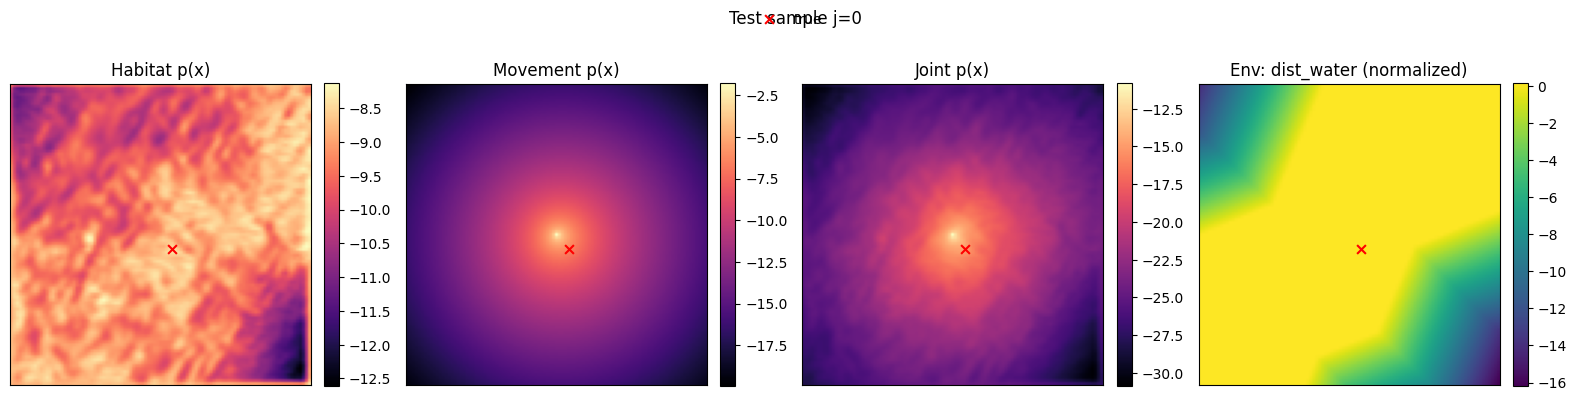

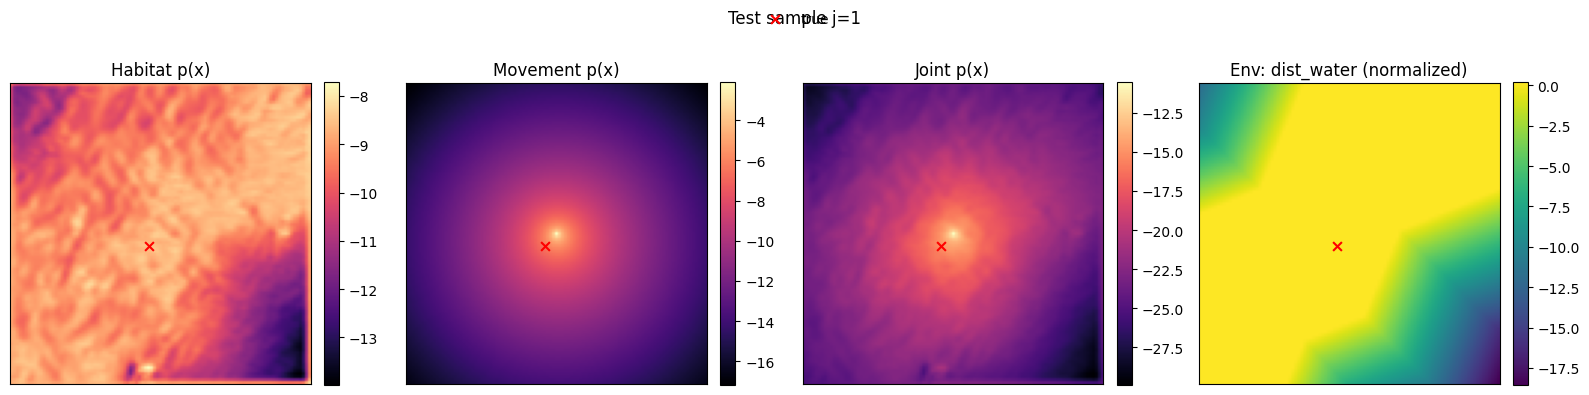

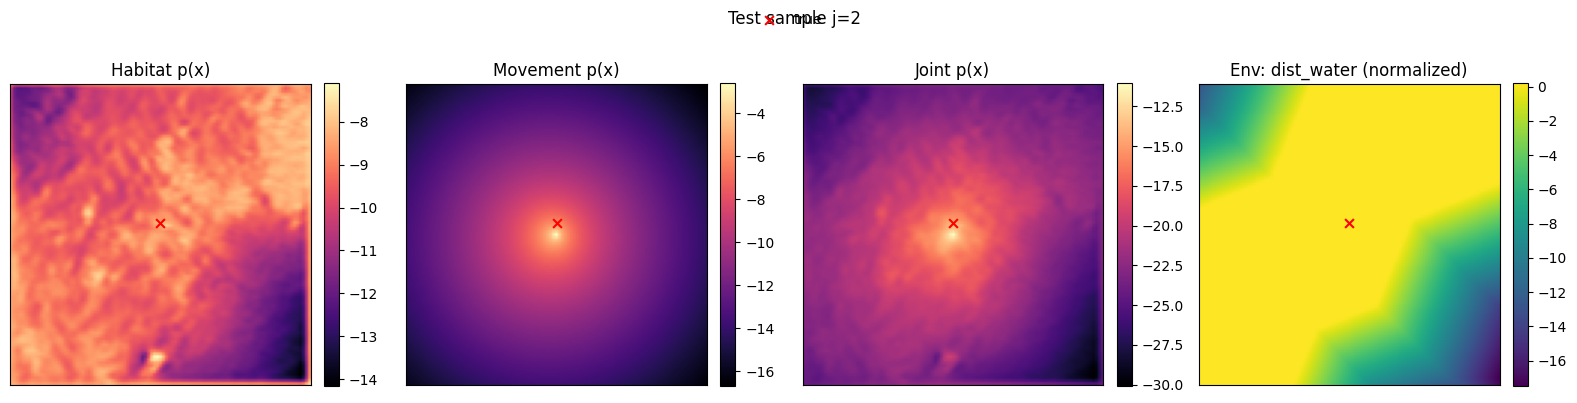

/Users/justinkay/movebench/movebench/datasets/chips.py:418: UserWarning: Observed endpoint fell outside chip grid at least once; those samples will have an all-zero target (and should be ignored by losses/metrics). Example: point_id_start=1544 (row,col)=(-5,41) chip(H,W)=(101,101).
  warnings.warn(


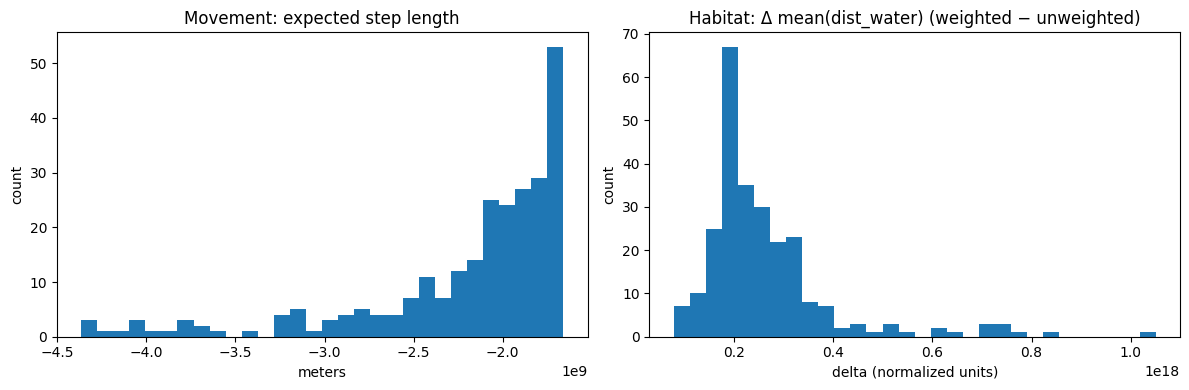

Expected step length: mean=-2200059904.0m, median=-1986251904.0m
Habitat Δ mean(dist_water): mean=262057927781646336.0000 (negative => prefers lower values)


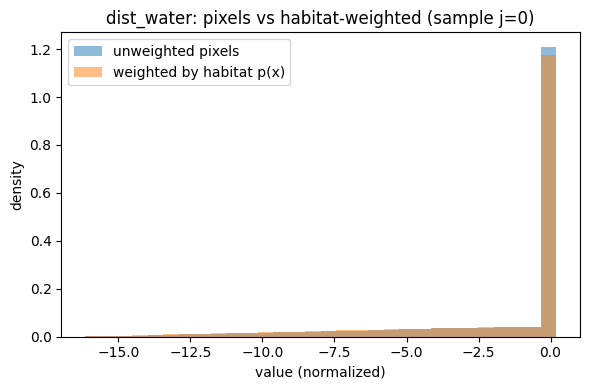

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# --- Settings ---
n_show = 3
max_batches = 8  # for distribution diagnostics (kept small; chips are expensive)

# Pick an environmental layer to visualize (prefer distance-to-water).
plan = test_ds.chips.plan
layer_candidates = ['dist_water', 'dem', 'slope']
viz_layer = None
viz_channel = None
for name in layer_candidates:
    if name in plan.layers_in_order:
        s, e = plan.layer_slice(name)
        if (e - s) == 1:
            viz_layer = name
            viz_channel = int(s)
            break
if viz_layer is None:
    raise ValueError(f'No 1-channel layer found among {layer_candidates}.')
print(f'Visualizing env layer {viz_layer!r} at channel index {viz_channel}')


@torch.no_grad()
def joint_prob(hab_log: torch.Tensor, mov_log: torch.Tensor) -> torch.Tensor:
    joint = hab_log + mov_log  # (B,H,W)
    # B, H, W = joint.shape
    # return torch.softmax(joint.view(B, H * W), dim=1).view(B, H, W)
    return joint


@torch.no_grad()
def show_predictions(x1, x2, x3, y, *, n_show: int = 3) -> None:
    model.eval()
    x1 = x1.to(device)
    x2 = x2.to(device)
    x3 = x3.to(device)
    y = y.to(device)

    out = model((x1, x2, x3))
    hab_log = out[..., 0]
    mov_log = out[..., 1]

    hab_p = hab_log
    mov_p = mov_log
    joint_p = joint_prob(hab_log, mov_log)

    B, H, W = hab_p.shape
    center_rc = (H // 2, W // 2)

    ysum = y.view(B, -1).sum(dim=1)
    idxs = torch.where(ysum > 0.5)[0].tolist()[:n_show]
    if not idxs:
        idxs = list(range(min(n_show, B)))

    for j in idxs:
        true_rc = None
        if float(ysum[j].item()) > 0.5:
            true_flat = int(torch.argmax(y[j]).item())
            true_rc = (true_flat // W, true_flat % W)

        pred_flat = int(torch.argmax(joint_p[j]).item())
        pred_rc = (pred_flat // W, pred_flat % W)

        fig, axes = plt.subplots(1, 4, figsize=(16, 4))
        panels = [
            ('Habitat p(x)', hab_p[j].detach().cpu().numpy(), 'magma'),
            ('Movement p(x)', mov_p[j].detach().cpu().numpy(), 'magma'),
            ('Joint p(x)', joint_p[j].detach().cpu().numpy(), 'magma'),
            (f'Env: {viz_layer} (normalized)', x1[j, viz_channel].detach().cpu().numpy(), 'viridis'),
        ]

        for ax, (title, img, cmap) in zip(axes, panels):
            im = ax.imshow(img, cmap=cmap)
            ax.set_title(title)
            ax.set_xticks([])
            ax.set_yticks([])
            # ax.scatter([center_rc[1]], [center_rc[0]], c='yellow', s=30, marker='+', label='start')
            # ax.scatter([pred_rc[1]], [pred_rc[0]], c='white', s=30, marker='o', label='pred')
            if true_rc is not None:
                ax.scatter([true_rc[1]], [true_rc[0]], c='red', s=40, marker='x', label='true')
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
        fig.suptitle(f'Test sample j={j}', y=1.02)
        plt.tight_layout()
        plt.show()


# --- 1) Habitat + movement + joint predictions on a few test points ---
batch = next(iter(test_loader))
show_predictions(*batch, n_show=n_show)


# --- 2) Learned distribution diagnostics ---
model.eval()
dist_layer = model.model.movement_grid_output.distance_layer.to(device)  # (H,W), meters

expected_step_m = []
habitat_env_delta = []

with torch.no_grad():
    for b_i, (x1, x2, x3, y) in enumerate(test_loader):
        if b_i >= max_batches:
            break
        x1 = x1.to(device)
        x2 = x2.to(device)
        x3 = x3.to(device)

        out = model((x1, x2, x3))
        hab_log = out[..., 0]
        mov_log = out[..., 1]

        mov_p = mov_log #.exp()
        expected_step_m.append((mov_p * dist_layer).sum(dim=(1, 2)).detach().cpu())

        env_map = x1[:, viz_channel, :, :]
        mask = (x1.abs().sum(dim=1) > 0).to(env_map.dtype)  # heuristic valid-pixel mask

        hab_p = hab_log * mask # hab_log.exp() * mask
        hab_p = hab_p / hab_p.sum(dim=(1, 2), keepdim=True).clamp_min(1e-12)

        hab_wmean = (hab_p * env_map).sum(dim=(1, 2))
        env_mean = (env_map * mask).sum(dim=(1, 2)) / mask.sum(dim=(1, 2)).clamp_min(1.0)
        habitat_env_delta.append((hab_wmean - env_mean).detach().cpu())

expected_step_m = torch.cat(expected_step_m).numpy()
habitat_env_delta = torch.cat(habitat_env_delta).numpy()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(expected_step_m, bins=30)
ax[0].set_title('Movement: expected step length')
ax[0].set_xlabel('meters')
ax[0].set_ylabel('count')

ax[1].hist(habitat_env_delta, bins=30)
ax[1].set_title(f'Habitat: Δ mean({viz_layer}) (weighted − unweighted)')
ax[1].set_xlabel('delta (normalized units)')
ax[1].set_ylabel('count')

plt.tight_layout()
plt.show()

print(f'Expected step length: mean={expected_step_m.mean():.1f}m, median={np.median(expected_step_m):.1f}m')
print(f'Habitat Δ mean({viz_layer}): mean={habitat_env_delta.mean():.4f} (negative => prefers lower values)')


# --- 3) One sample: env histogram vs habitat-weighted env histogram ---
with torch.no_grad():
    x1, x2, x3, y = batch
    x1 = x1.to(device)
    x2 = x2.to(device)
    x3 = x3.to(device)
    out = model((x1, x2, x3))
    hab_p = out[..., 0]

j = 0
env_map = x1[j, viz_channel].detach().cpu().numpy()
weights = hab_p[j].detach().cpu().numpy()

mask = (np.abs(x1[j].detach().cpu().numpy()).sum(axis=0) > 0)
vals = env_map[mask]
w = weights[mask]
w = w / (w.sum() + 1e-12)

plt.figure(figsize=(6, 4))
plt.hist(vals, bins=30, density=True, alpha=0.5, label='unweighted pixels')
plt.hist(vals, bins=30, density=True, alpha=0.5, weights=w, label='weighted by habitat p(x)')
plt.title(f'{viz_layer}: pixels vs habitat-weighted (sample j={j})')
plt.xlabel('value (normalized)')
plt.ylabel('density')
plt.legend()
plt.tight_layout()
plt.show()
